[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/hentablihamza/practical-cheminformatics-course/blob/main/notebooks/12_virtual_screening_enrichment.ipynb)

# 12 · Virtual Screening and Enrichment Metrics

*Practical Cheminformatics Course · Hamza Hentabli, Ph.D. · ~50 min*

Virtual screening ranks a large library so that the few real actives rise to the top, where a
chemist can afford to test them. Success is measured by **early enrichment**, not overall accuracy.
We use the curated EGFR dataset (actives = pIC50 >= 7) as a realistic, imbalanced screening problem.

**Learning objectives.** By the end of this notebook you will be able to:

- rank a library by similarity to known actives (ligand-based virtual screening)
- rank a library with a trained classifier (machine-learning virtual screening)
- compute enrichment factors (EF), BEDROC, ROC curves, and AUC
- understand why early enrichment matters more than overall AUC in screening

In [1]:
# Setup: installs dependencies on Google Colab and locates the course data.
# Running locally? Install requirements.txt once and this cell does nothing extra.
import os, sys, subprocess

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", 'rdkit', 'scikit-learn'], check=True)
    if not os.path.isdir("practical-cheminformatics-course"):
        subprocess.run(["git", "clone", "-q", "--depth", "1",
                        "https://github.com/hentablihamza/practical-cheminformatics-course.git"], check=True)
    DATA_DIR = "practical-cheminformatics-course/data"
else:
    DATA_DIR = "../data" if os.path.isdir("../data") else "data"

print("Running on Colab:", IN_COLAB, "| data folder:", DATA_DIR)

Running on Colab: False | data folder: ../data


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from rdkit import Chem, DataStructs, RDLogger
from rdkit.Chem import Draw
from rdkit.Chem.Draw import IPythonConsole
RDLogger.DisableLog("rdApp.*")
from rdkit.Chem import rdFingerprintGenerator
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score, roc_curve

egfr = pd.read_csv(f"{DATA_DIR}/egfr_chembl37_ic50.csv")
egfr["mol"] = egfr["smiles"].apply(Chem.MolFromSmiles)
egfr["label"] = (egfr["p_activity"] >= 7).astype(int)     # active = pIC50 >= 7 (<= 100 nM)
print("compounds:", len(egfr), "| actives:", int(egfr["label"].sum()),
      f"({egfr['label'].mean():.1%})")

compounds: 6871 | actives: 3562 (51.8%)


## 1. Build a screening split

We split into a reference/training part and a **screening library** we pretend is unknown.

In [3]:
mfpgen = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=2048)
egfr["fp"] = [mfpgen.GetFingerprint(m) for m in egfr["mol"]]
X = np.array([mfpgen.GetFingerprintAsNumPy(m) for m in egfr["mol"]])
y = egfr["label"].values

idx = np.arange(len(egfr))
train_idx, screen_idx = train_test_split(idx, test_size=0.4, stratify=y, random_state=42)
print(len(train_idx), "reference compounds |", len(screen_idx), "screening library")
print("actives in library:", int(y[screen_idx].sum()), f"({y[screen_idx].mean():.1%})")

4122 reference compounds | 2749 screening library
actives in library: 1425 (51.8%)


## 2. Method A: ligand-based similarity screening

Score each library compound by its **maximum** Tanimoto similarity to the known training actives,
the classic nearest-neighbour virtual screen.

In [4]:
active_fps = [egfr["fp"].iloc[i] for i in train_idx if y[i] == 1]
sim_score = np.array([max(DataStructs.BulkTanimotoSimilarity(egfr["fp"].iloc[i], active_fps))
                      for i in screen_idx])
print("similarity scores:", sim_score.min().round(2), "to", sim_score.max().round(2))

similarity scores: 0.15 to 1.0


## 3. Method B: machine-learning screening

Train a random forest classifier and score the library by its predicted probability of being active.

In [5]:
clf = RandomForestClassifier(n_estimators=500, random_state=0, n_jobs=-1, class_weight="balanced")
clf.fit(X[train_idx], y[train_idx])
ml_score = clf.predict_proba(X[screen_idx])[:, 1]

## 4. Enrichment metrics

Definitions, with y_true the labels and *score* the ranking:

- **Enrichment factor at x%** (EF): how many more actives you find in the top x% than by random picking.
  EF = (actives in top x% / compounds in top x%) / (overall active fraction).
- **BEDROC**: a smooth early-enrichment score (0-1) that weights the very top of the list most.
- **ROC-AUC**: probability a random active ranks above a random inactive (0.5 = random, 1 = perfect).

In [6]:
def enrichment_factor(y_true, score, frac):
    n = max(1, int(round(len(score) * frac)))
    top = np.argsort(score)[::-1][:n]
    active_rate_overall = y_true.mean()
    return (y_true[top].mean() / active_rate_overall) if active_rate_overall > 0 else np.nan

def bedroc(y_true, score, alpha=20.0):
    """Boltzmann-Enhanced Discrimination of ROC (Truchon & Bayly, JCIM 2007)."""
    order = np.argsort(score)[::-1]
    yt = y_true[order]
    N, n = len(yt), int(y_true.sum())
    if n == 0 or n == N:
        return np.nan
    ranks = np.where(yt == 1)[0] + 1            # 1-indexed ranks of the actives
    ra = n / N
    rie = (np.sum(np.exp(-alpha * ranks / N)) / n) /           ((1 / N) * (1 - np.exp(-alpha)) / (np.exp(alpha / N) - 1))
    return (rie * ra * np.sinh(alpha / 2) /
            (np.cosh(alpha / 2) - np.cosh(alpha / 2 - alpha * ra))
            + 1 / (1 - np.exp(alpha * (1 - ra))))

yt = y[screen_idx]
rows = []
for name, score in [("similarity (ligand-based)", sim_score), ("random forest (ML)", ml_score)]:
    rows.append({
        "method": name,
        "ROC-AUC": roc_auc_score(yt, score),
        "EF 1%": enrichment_factor(yt, score, 0.01),
        "EF 5%": enrichment_factor(yt, score, 0.05),
        "EF 10%": enrichment_factor(yt, score, 0.10),
        "BEDROC(a=20)": bedroc(yt, score, 20.0),
    })
pd.DataFrame(rows).round(3)

,method,ROC-AUC,EF 1%,EF 5%,EF 10%,BEDROC(a=20)
0,similarity (ligand-based),0.833,1.643,1.605,1.719,0.868
1,random forest (ML),0.918,1.929,1.887,1.880,0.972


A random screen has EF = 1 at every depth. EF 1% well above 1 means the method concentrates
actives at the very top of the list, which is what matters when you can only test a handful.

## 5. ROC curves

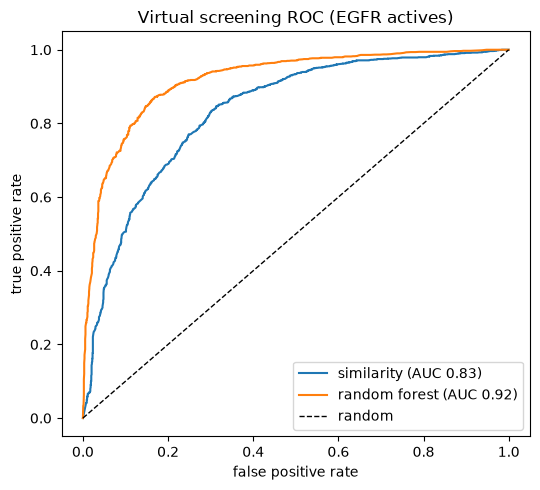

In [7]:
fig, ax = plt.subplots(figsize=(5.5, 5))
for name, score in [("similarity", sim_score), ("random forest", ml_score)]:
    fpr, tpr, _ = roc_curve(yt, score)
    ax.plot(fpr, tpr, label=f"{name} (AUC {roc_auc_score(yt, score):.2f})")
ax.plot([0, 1], [0, 1], "k--", lw=1, label="random")
ax.set_xlabel("false positive rate"); ax.set_ylabel("true positive rate")
ax.set_title("Virtual screening ROC (EGFR actives)"); ax.legend(loc="lower right")
plt.tight_layout(); plt.show()

## 6. The enrichment curve: what a chemist actually cares about

Fraction of all actives recovered as you screen deeper down the ranked list.

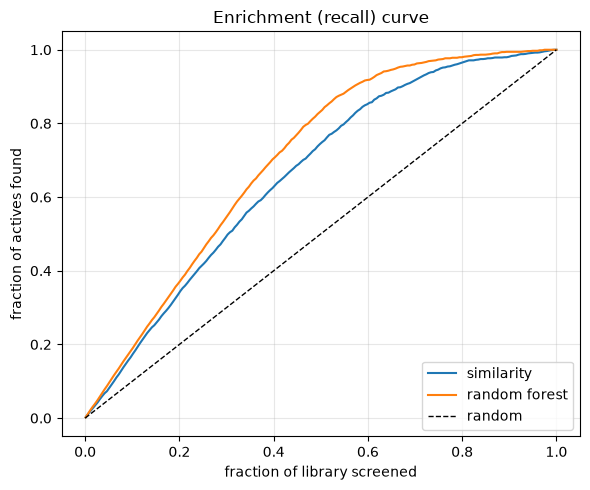

In [8]:
fig, ax = plt.subplots(figsize=(6, 5))
depths = np.linspace(0.001, 1, 200)
for name, score in [("similarity", sim_score), ("random forest", ml_score)]:
    order = np.argsort(score)[::-1]
    found = np.cumsum(yt[order]) / yt.sum()
    ax.plot(depths, [found[min(len(found) - 1, int(d * len(found)))] for d in depths], label=name)
ax.plot([0, 1], [0, 1], "k--", lw=1, label="random")
ax.set_xlabel("fraction of library screened"); ax.set_ylabel("fraction of actives found")
ax.set_title("Enrichment (recall) curve"); ax.legend(loc="lower right"); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

In [9]:
for frac in [0.01, 0.05, 0.10, 0.20]:
    order = np.argsort(ml_score)[::-1][:int(frac * len(yt))]
    print(f"Screening the top {frac:4.0%}: {yt[order].sum():3d} of {int(yt.sum())} actives recovered "
          f"({yt[order].mean():.0%} of that slice are active)")

Screening the top   1%:  27 of 1425 actives recovered (100% of that slice are active)
Screening the top   5%: 134 of 1425 actives recovered (98% of that slice are active)
Screening the top  10%: 267 of 1425 actives recovered (97% of that slice are active)
Screening the top  20%: 526 of 1425 actives recovered (96% of that slice are active)


### ✏️ Exercise 1

Compute EF at 2% for both methods. Which method gives better *early* enrichment?

In [10]:
# Your code here

<details>
<summary><b>Show solution</b></summary>

```python
for name, score in [("similarity", sim_score), ("random forest", ml_score)]:
    print(f"{name}: EF 2% = {enrichment_factor(yt, score, 0.02):.2f}")
```

</details>

### ✏️ Exercise 2

A pure descriptor model: train a random forest on MW, logP, TPSA, HBD, HBA (from Notebook 03) and report its ROC-AUC and EF 5%. Do physicochemical properties alone screen well?

In [11]:
# Your code here

<details>
<summary><b>Show solution</b></summary>

```python
from rdkit.Chem import Descriptors, Crippen, rdMolDescriptors
def phys(m):
    return [Descriptors.MolWt(m), Crippen.MolLogP(m), rdMolDescriptors.CalcTPSA(m),
            rdMolDescriptors.CalcNumHBD(m), rdMolDescriptors.CalcNumHBA(m)]
Xp = np.array([phys(m) for m in egfr["mol"]])
clf_p = RandomForestClassifier(n_estimators=500, random_state=0, n_jobs=-1,
                               class_weight="balanced").fit(Xp[train_idx], y[train_idx])
sp = clf_p.predict_proba(Xp[screen_idx])[:, 1]
print(f"ROC-AUC {roc_auc_score(yt, sp):.3f} | EF 5% {enrichment_factor(yt, sp, 0.05):.2f}")
```

</details>

### ✏️ Exercise 3

How many compounds would you have to test to find half of all actives, using the random-forest ranking? Express it as a fraction of the library.

In [12]:
# Your code here

<details>
<summary><b>Show solution</b></summary>

```python
order = np.argsort(ml_score)[::-1]
cum = np.cumsum(yt[order])
k = int(np.searchsorted(cum, yt.sum() / 2) + 1)
print(f"{k} compounds = {k / len(yt):.1%} of the library to recover 50% of actives")
```

</details>

## Key takeaways

- Judge a virtual screen by **early enrichment** (EF at 1-5%, BEDROC), not overall accuracy.
- Both similarity and ML rankings beat random by a wide margin; ML usually wins at the very top.
- ROC-AUC summarizes the whole ranking but can hide poor early enrichment.

## Course complete

You have gone from a CSV of molecules to curated data, descriptors, models, honest validation, and a
virtual screen. Suggested next steps: swap in your own target with [chembl-easy], benchmark your splits
with [qsar-split-bench], and curate at scale with [chem-curate].

[chembl-easy]: https://github.com/hentablihamza/chembl-easy
[qsar-split-bench]: https://github.com/hentablihamza/qsar-split-bench
[chem-curate]: https://github.com/hentablihamza/chem-curate